<a href="https://colab.research.google.com/github/Nidhiwa/telco-customer-churn-analysis/blob/main/notebooks/Telco_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# --- IMPORT CORE PYTHON LIBRARIES ---
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- ENABLE SQL MAGIC COMMANDS IN COLAB ---

%load_ext sql


# --- LOAD RAW DATASET ---
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Loaded: {df.shape[0]} rows and {df.shape[1]} columns")
df.head()

Dataset Loaded: 7043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# --- CHECK DATA TYPES & NON-NULL COUNTS ---

print(" DATASET SCHEMA & DATA TYPES ")
df.info()                                           # Notice TotalCharges is 'object' (text) instead of 'float64' (number)!

# --- CHECK FOR DUPLICATE CUSTOMERS ---

duplicates = df["customerID"].duplicated().sum()
print(f"\n DUPLICATE CUSTOMER IDS: {duplicates} ")

# --- 3. FIND HIDDEN BLANK SPACES IN TOTALCHARGES ---

blank_rows = df[df["TotalCharges"].str.strip() == ""]

print(f"\n HIDDEN BLANK ROWS IN TOTALCHARGES: {len(blank_rows)}")

display(blank_rows[["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]])

 DATASET SCHEMA & DATA TYPES 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBil

,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


In [8]:
# CONVERT TOTALCHARGES TO NUMERIC
# errors="coerce" turns any non-numeric text (like blank spaces " ") into NaN (Not a Number)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# IMPUTE MISSING VALUES
# Fill those 11 NaN values with 0.0 because tenure=0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# CREATE BINARY CHURN FLAG (1 = Yes, 0 = No)
# Mapping Yes/No to 1/0 lets us calculate Churn Rate % simply by taking the AVG() in SQL!
df["Churn_Flag"] = df["Churn"].map({"Yes": 1, "No": 0})

# --- 4. ENGINEER TENURE COHORTS ---
# pd.cut slices continuous tenure months (0 to 72) into 4 clean business categories
bins = [-1, 12, 24, 48, 72]                         # -1 ensures customers with tenure=0 are included in the first bin
labels = ["0-1 Year", "1-2 Years", "2-4 Years", "4-6 Years"]
df["Tenure_Group"] = pd.cut(df["tenure"], bins=bins, labels=labels)

# --- 5. VERIFY CLEAN DATASET ---
print("Remaining missing values across entire dataset:", df.isna().sum().sum())
df[["customerID", "tenure", "Tenure_Group", "Contract", "MonthlyCharges", "TotalCharges", "Churn_Flag"]].head()

Remaining missing values across entire dataset: 0


,customerID,tenure,Tenure_Group,Contract,MonthlyCharges,TotalCharges,Churn_Flag
0,7590-VHVEG,1,0-1 Year,Month-to-month,29.85,29.85,0
1,5575-GNVDE,34,2-4 Years,One year,56.95,1889.50,0
2,3668-QPYBK,2,0-1 Year,Month-to-month,53.85,108.15,1
3,7795-CFOCW,45,2-4 Years,One year,42.30,1840.75,0
4,9237-HQITU,2,0-1 Year,Month-to-month,70.70,151.65,1


In [23]:
# CREATE SQLITE DATABASE & WRITE TABLE ---
# --- 1. CREATE SQLITE DATABASE & WRITE TABLE ---
conn = sqlite3.connect("telco.db")
df.to_sql("telco_customers", conn, index=False, if_exists="replace")



7043

In [24]:
query_kpis = """
SELECT
    COUNT(customerID) AS Total_Customers,
    SUM(Churn_Flag) AS Churned_Customers,
    ROUND(AVG(Churn_Flag) * 100, 2) AS Overall_Churn_Rate_Pct,
    ROUND(SUM(MonthlyCharges), 2) AS Total_Monthly_Revenue,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 2) AS Monthly_Revenue_At_Risk,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END) * 12, 2) AS Annualized_Revenue_At_Risk
FROM telco_customers;
"""
kpi_summary = pd.read_sql_query(query_kpis, conn)   # Executes SQL and stores result in 'kpi_summary'
print("=== 1. EXECUTIVE KPI SUMMARY ===")
display(kpi_summary)

=== 1. EXECUTIVE KPI SUMMARY ===


,Total_Customers,Churned_Customers,Overall_Churn_Rate_Pct,Total_Monthly_Revenue,Monthly_Revenue_At_Risk,Annualized_Revenue_At_Risk
0,7043,1869,26.54,456116.6,139130.85,1669570.2


In [25]:

# CHURN RATE & REVENUE LOST BY CONTRACT TYPE ===
query_contract = """
SELECT
    Contract,
    COUNT(customerID) AS Customers,
    SUM(Churn_Flag) AS Churned,
    ROUND(AVG(Churn_Flag) * 100, 2) AS Churn_Rate_Pct,
    ROUND(AVG(MonthlyCharges), 2) AS Avg_Monthly_Charge,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN MonthlyCharges ELSE 0 END), 2) AS Monthly_Revenue_Lost
FROM telco_customers
GROUP BY Contract
ORDER BY Churn_Rate_Pct DESC;
"""
contract_df = pd.read_sql_query(query_contract, conn) # Stores result in 'contract_df' for Chart 1
print("\n=== 2. CHURN & REVENUE RISK BY CONTRACT ===")
display(contract_df)



=== 2. CHURN & REVENUE RISK BY CONTRACT ===


,Contract,Customers,Churned,Churn_Rate_Pct,Avg_Monthly_Charge,Monthly_Revenue_Lost
0,Month-to-month,3875,1655,42.71,66.40,120847.10
1,One year,1473,166,11.27,65.05,14118.45
2,Two year,1695,48,2.83,60.77,4165.30


In [26]:
# QUERY 3: CHURN RATE BY TENURE COHORT ===
query_tenure = """
SELECT
    Tenure_Group,
    COUNT(customerID) AS Customers,
    ROUND(AVG(Churn_Flag) * 100, 2) AS Churn_Rate_Pct
FROM telco_customers
GROUP BY Tenure_Group;
"""
tenure_df = pd.read_sql_query(query_tenure, conn)     # Stores result in 'tenure_df' for Chart 2
print("\n=== 3. CHURN RATE BY TENURE COHORT ===")
display(tenure_df)



=== 3. CHURN RATE BY TENURE COHORT ===


,Tenure_Group,Customers,Churn_Rate_Pct
0,0-1 Year,2186,47.44
1,1-2 Years,1024,28.71
2,2-4 Years,1594,20.39
3,4-6 Years,2239,9.51


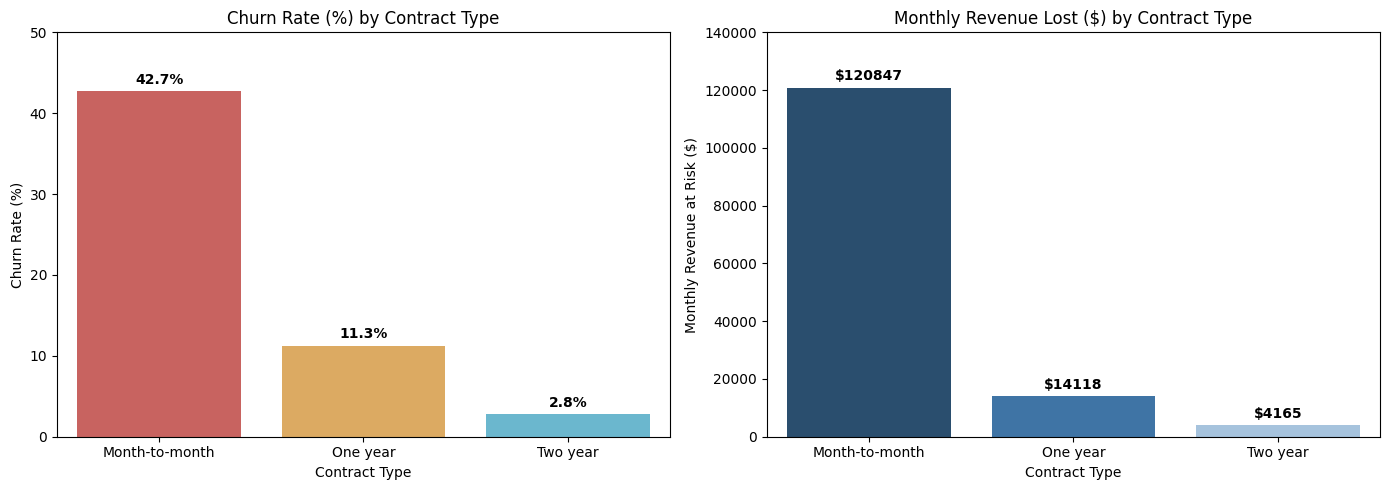

In [27]:
# --- CREATE A 1-ROW, 2-COLUMN FIGURE ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))      # fig is the overall canvas; axes[0] is left plot, axes[1] is right plot

# --- LEFT CHART: CHURN RATE (%) BY CONTRACT ---
sns.barplot(
    data=contract_df,                               # Uses the DataFrame created by our %%sql query in Cell 6
    x="Contract",                                   # Categories on the horizontal x-axis
    y="Churn_Rate_Pct",                             # Values on the vertical y-axis
    hue="Contract",                                 # Maps colors cleanly to each contract bar
    legend=False,                                   # Hides redundant legend since x-axis already labels each bar
    palette=["#D9534F", "#F0AD4E", "#5BC0DE"],      # Red (high risk), Orange (medium), Blue (low risk)
    ax=axes[0]                                      # Places this chart on the left subplot
)
axes[0].set_title("Churn Rate (%) by Contract Type")
axes[0].set_xlabel("Contract Type")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 50)                             # Adds headroom above the tallest bar (42.7%) so labels fit cleanly

# Add exact percentage labels on top of every bar
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")

# --- RIGHT CHART: MONTHLY REVENUE LOST ($) BY CONTRACT ---
sns.barplot(
    data=contract_df,
    x="Contract",
    y="Monthly_Revenue_Lost",
    hue="Contract",
    legend=False,
    palette=["#1F4E79", "#2E75B6", "#9DC3E6"],      # Dark-to-light corporate blue gradient
    ax=axes[1]                                      # Places this chart on the right subplot
)
axes[1].set_title("Monthly Revenue Lost ($) by Contract Type")
axes[1].set_xlabel("Contract Type")
axes[1].set_ylabel("Monthly Revenue at Risk ($)")
axes[1].set_ylim(0, 140000)                         # Adds headroom above $120,847

# Add exact dollar labels on top of every bar
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="$%.0f", padding=3, fontweight="bold")

plt.tight_layout()                                  # Automatically adjusts spacing so titles and labels never overlap
plt.show()                                          # Renders the final figure in Colab


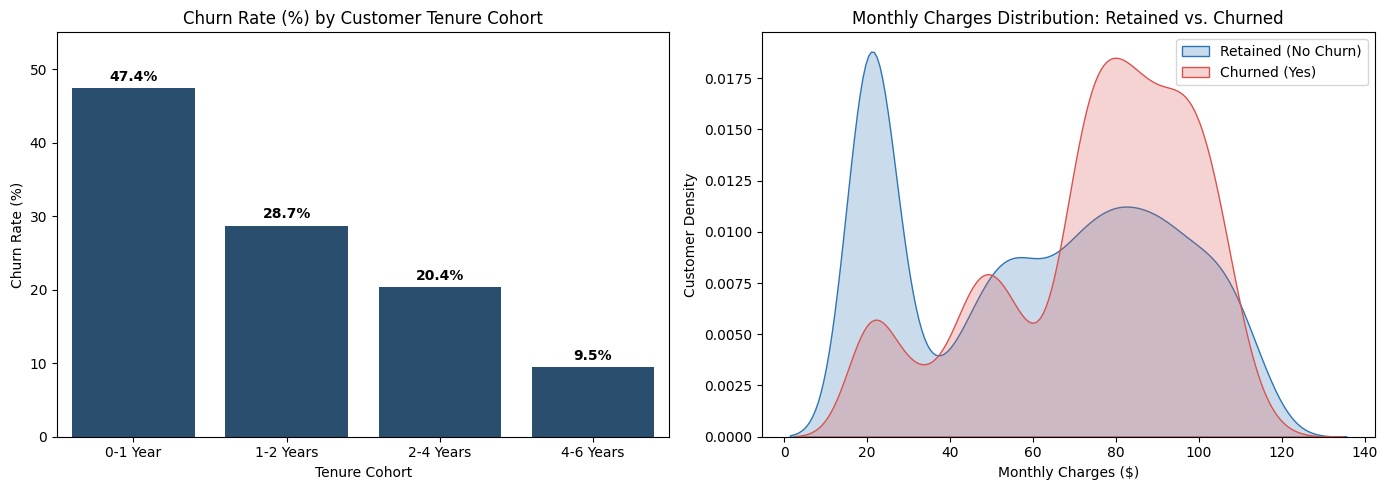

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- LEFT CHART: CHURN RATE BY TENURE COHORT ---
order_list = ["0-1 Year", "1-2 Years", "2-4 Years", "4-6 Years"] # Enforces chronological order on the x-axis

sns.barplot(
    data=tenure_df,                                 # Uses the DataFrame created by our %%sql query in Cell 7
    x="Tenure_Group",
    y="Churn_Rate_Pct",
    order=order_list,                               # Applies our chronological list
    color="#1F4E79",                                # Single cohesive navy color
    ax=axes[0]
)
axes[0].set_title("Churn Rate (%) by Customer Tenure Cohort")
axes[0].set_xlabel("Tenure Cohort")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 55)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")

# --- RIGHT CHART: MONTHLY CHARGES DISTRIBUTION (KDE PLOT) ---
# sns.kdeplot draws a smooth probability curve showing where customer bills cluster
sns.kdeplot(
    data=df[df["Churn"] == "No"],                   # Filters only retained customers
    x="MonthlyCharges",
    fill=True,                                      # Shades the area under the curve
    label="Retained (No Churn)",
    color="#2E75B6",
    ax=axes[1]
)
sns.kdeplot(
    data=df[df["Churn"] == "Yes"],                  # Filters only churned customers
    x="MonthlyCharges",
    fill=True,
    label="Churned (Yes)",
    color="#D9534F",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges Distribution: Retained vs. Churned")
axes[1].set_xlabel("Monthly Charges ($)")
axes[1].set_ylabel("Customer Density")
axes[1].legend()                                    # Displays the legend distinguishing Retained vs. Churned

plt.tight_layout()
plt.show()


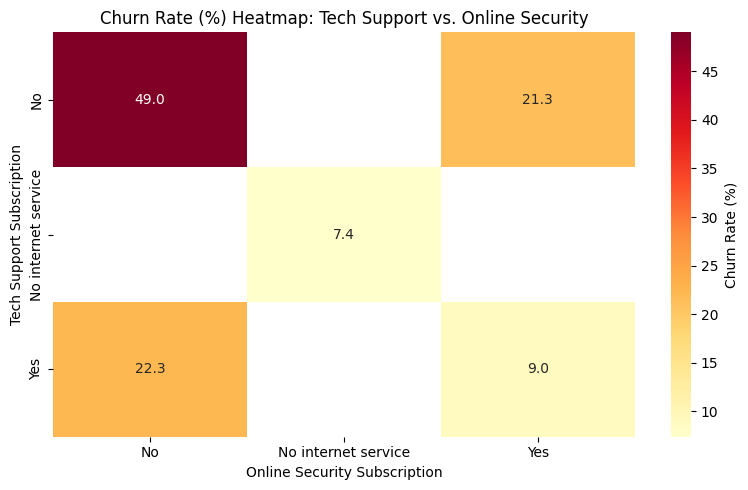

In [29]:
# --- 1. CREATE A PIVOT TABLE MATRIX ---
# Rows = TechSupport, Columns = OnlineSecurity, Cell Values = Average Churn Rate (%)
pivot_services = df.pivot_table(
    index="TechSupport",
    columns="OnlineSecurity",
    values="Churn_Flag",
    aggfunc=lambda x: round(x.mean() * 100, 1)      # Calculates mean of 1/0 flag * 100, rounded to 1 decimal place
)

# --- 2. PLOT HEATMAP ---
plt.figure(figsize=(8, 5))
sns.heatmap(
    pivot_services,
    annot=True,                                     # Prints the exact churn percentage inside every square
    fmt=".1f",                                      # Formats numbers to 1 decimal place
    cmap="YlOrRd",                                  # Color scale: Yellow (low churn) -> Orange -> Red (high churn)
    cbar_kws={"label": "Churn Rate (%)"}            # Labels the color bar legend on the right
)
plt.title("Churn Rate (%) Heatmap: Tech Support vs. Online Security")
plt.xlabel("Online Security Subscription")
plt.ylabel("Tech Support Subscription")
plt.tight_layout()
plt.show()



## Executive Summary & Recommendations
1. **Overall Churn & Revenue Risk:** 26.54% of customers (1,869 out of 7,043) churned, putting **~$139,130/month (~$1.67M annualized)** in recurring revenue at risk.
2. **Primary Churn Drivers:** **Month-to-month contracts** suffer a **42.7% churn rate** and account for **>86% of lost monthly revenue**, while customers in their **first 12 months (`0–1 Year` cohort)** churn at **47.4%**.
3. **Actionable Next Steps:**
   * Offer a 10–15% loyalty discount to migrate **Month-to-Month** subscribers onto **1-Year contracts**.
   * Launch a structured **90-day onboarding check-in cadence** to lower first-year attrition.
   * Bundle **Tech Support** and **Online Security** free for 6 months for **Fiber Optic** customers to reduce churn by >50% in high-bill tiers.